# 🏠 Building Insurance Claim Prediction

**Goal:** predict whether a customer's building will have an insurance claim (`Claim`: 0 = no claim, 1 = claim) using building and policy characteristics.
developed by

NAME	                REG NO
MAYEGA JOEL	            25/08/BDA/U/0005
MIYINGO DERRICK	        25/08/BDA/U/0004
BWIRE EDRIN	            25/08/BDA/U/0007



**Workflow in this notebook**

1. Setup and data loading
2. Data quality checks (missing values, duplicates)
3. Exploratory data analysis (EDA)
4. Outlier detection and treatment
5. Data cleaning and imputation
6. Feature engineering
7. Preprocessing pipeline and encoding
8. Train/validation split and feature selection

> **Leakage rule used throughout:** every statistic (medians, IQR bounds, encoders) is learned from the **training data only** and then applied to the test data.

## 1. Setup

### 1.1 Import libraries and configure plotting
Load the libraries for data handling (`pandas`, `numpy`), visualization (`matplotlib`, `seaborn`) and Excel support (`openpyxl`, needed to read the `.xlsx` test file). Warnings are silenced to keep the output clean, and a default plot style and figure size are set so all charts look consistent.

In [1]:
import openpyxl

print(openpyxl.__version__)
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Libraries loaded successfully!")


3.1.5
Libraries loaded successfully!


### 1.2 Load the datasets
Read the training data from CSV and the test data from Excel, then print their dimensions (rows, columns) and preview the first five records of each. This is a quick sanity check that both files loaded correctly and that their columns look consistent. The test set should have one fewer column, since it has no `Claim` target.

In [2]:

# Load training dataset
train = pd.read_csv("train_data.csv")

# Load testing dataset
test = pd.read_excel("test_data.xlsx")

# Display dimensions
print("TRAINING DATA:", train.shape)
print("TESTING DATA:", test.shape)

# Display first five records
display(train.head())
display(test.head())


TRAINING DATA: (7160, 14)
TESTING DATA: (3069, 13)


,Customer Id,YearOfObservation,Insured_Period,Residential,Building_Painted,Building_Fenced,Garden,Settlement,Building Dimension,Building_Type,Date_of_Occupancy,NumberOfWindows,Geo_Code,Claim
0,H14663,2013,1.0,0,N,V,V,U,290.0,1,1960.0,.,1053,0
1,H2037,2015,1.0,0,V,N,O,R,490.0,1,1850.0,4,1053,0
2,H3802,2014,1.0,0,N,V,V,U,595.0,1,1960.0,.,1053,0
3,H3834,2013,1.0,0,V,V,V,U,2840.0,1,1960.0,.,1053,0
4,H5053,2014,1.0,0,V,N,O,R,680.0,1,1800.0,3,1053,0


,Customer Id,YearOfObservation,Insured_Period,Residential,Building_Painted,Building_Fenced,Garden,Settlement,Building Dimension,Building_Type,Date_of_Occupancy,NumberOfWindows,Geo_Code
0,H11920,2013,1.000000,0,V,N,O,R,300.0,1,1960.0,3,3310
1,H11921,2016,0.997268,0,V,N,O,R,300.0,1,1960.0,3,3310
2,H9805,2013,0.369863,0,V,V,V,U,790.0,1,1960.0,.,3310
3,H7493,2014,1.000000,0,V,N,O,R,1405.0,1,2004.0,3,3321
4,H7494,2016,1.000000,0,V,N,O,R,1405.0,1,2004.0,3,3321


## 2. Data Understanding

### 2.1 Structure and summary statistics
- `.info()` shows column names, data types and non-null counts for both datasets.
- `.describe(include="all")` gives summary statistics for numeric *and* categorical columns (count, mean, std, min/max, unique values, top category).

Look for columns with unexpected data types, which often signal hidden problems such as placeholder characters in numeric columns.

In [3]:

# Dataset information
print("TRAINING DATA INFORMATION")
train.info()

print("\nTESTING DATA INFORMATION")
test.info()

# Statistical summary
display(train.describe(include="all").T)


TRAINING DATA INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7160 entries, 0 to 7159
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Customer Id         7160 non-null   object 
 1   YearOfObservation   7160 non-null   int64  
 2   Insured_Period      7160 non-null   float64
 3   Residential         7160 non-null   int64  
 4   Building_Painted    7160 non-null   object 
 5   Building_Fenced     7160 non-null   object 
 6   Garden              7153 non-null   object 
 7   Settlement          7160 non-null   object 
 8   Building Dimension  7054 non-null   float64
 9   Building_Type       7160 non-null   int64  
 10  Date_of_Occupancy   6652 non-null   float64
 11  NumberOfWindows     7160 non-null   object 
 12  Geo_Code            7058 non-null   object 
 13  Claim               7160 non-null   int64  
dtypes: float64(3), int64(4), object(7)
memory usage: 783.3+ KB

TESTING DATA INFOR

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Customer Id,7160,7160,H7470,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
YearOfObservation,7160.0,NaN,NaN,NaN,2013.669553,1.383769,2012.0,2012.0,2013.0,2015.0,2016.0
Insured_Period,7160.0,NaN,NaN,NaN,0.909758,0.239756,0.0,0.997268,1.0,1.0,1.0
Residential,7160.0,NaN,NaN,NaN,0.305447,0.460629,0.0,0.0,0.0,1.0,1.0
Building_Painted,7160,2,V,5382,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Building_Fenced,7160,2,N,3608,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Garden,7153,2,O,3602,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Settlement,7160,2,R,3610,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Building Dimension,7054.0,NaN,NaN,NaN,1883.72753,2278.157745,1.0,528.0,1083.0,2289.75,20940.0
Building_Type,7160.0,NaN,NaN,NaN,2.186034,0.940632,1.0,2.0,2.0,3.0,4.0


## 3. Data Quality Checks

### 3.1 Standardize and count missing values
`NumberOfWindows` uses a dot (`"."`) as a placeholder for missing data. Pandas does not treat this as missing, so it is replaced with `NaN`. A side-by-side report then shows how many values are missing in each column of the training and test sets.

In [4]:

# Convert dot markers into actual missing values
train["NumberOfWindows"] = (
    train["NumberOfWindows"].replace(".", np.nan)
)

test["NumberOfWindows"] = (
    test["NumberOfWindows"].replace(".", np.nan)
)

# Missing values in training

missing_train = train.isnull().sum()

# Missing values in testing
missing_test = test.isnull().sum()

missing_report = pd.DataFrame({
    "Training_Missing": missing_train,
    "Testing_Missing": missing_test
})

display(missing_report)


,Training_Missing,Testing_Missing
Building Dimension,106,13.0
Building_Fenced,0,0.0
Building_Painted,0,0.0
Building_Type,0,0.0
Claim,0,NaN
Customer Id,0,0.0
Date_of_Occupancy,508,728.0
Garden,7,4.0
Geo_Code,102,13.0
Insured_Period,0,0.0


### 3.2 Visualize missing values
A heatmap of the training data where each highlighted cell is a missing value. This shows *which* columns have gaps and whether the missingness is clustered in particular rows or spread randomly.

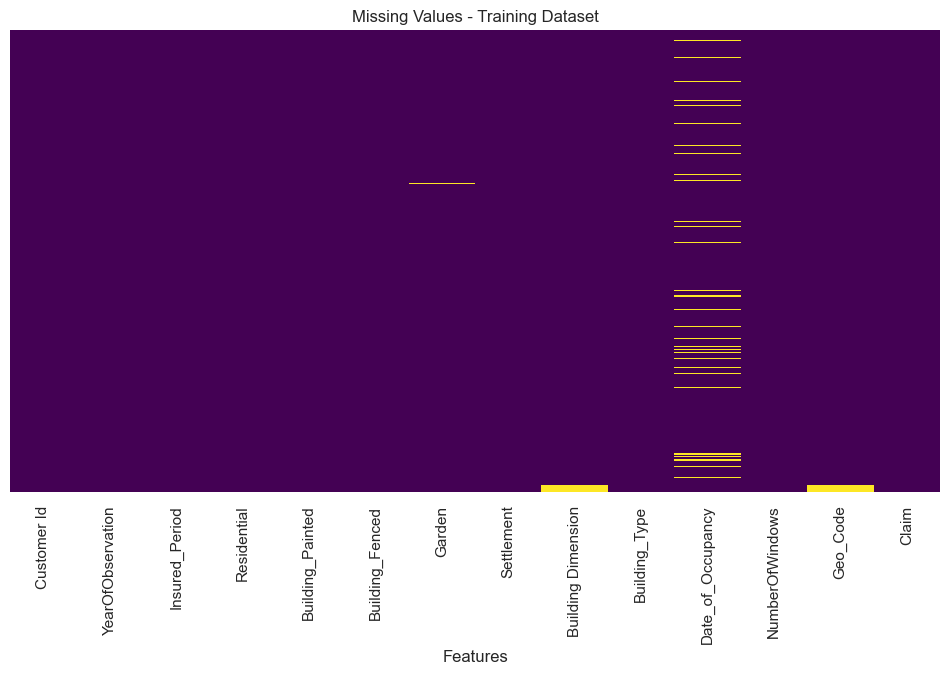

In [5]:

plt.figure(figsize=(12, 6))

sns.heatmap(
    train.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values - Training Dataset")
plt.xlabel("Features")
plt.show()


### 3.3 Check for duplicates
Count fully duplicated rows in the training data and repeated `Customer Id` values in both datasets. Customer IDs should be unique, so any repeats point to data-entry or merge problems that need investigation.

In [6]:

print("Training duplicates:", train.duplicated().sum())

print(
    "Duplicate training customer IDs:",
    train["Customer Id"].duplicated().sum()
)

print(
    "Duplicate testing customer IDs:",
    test["Customer Id"].duplicated().sum()
)


Training duplicates: 0
Duplicate training customer IDs: 0
Duplicate testing customer IDs: 0


## 4. Exploratory Data Analysis (EDA)

### 4.1 Target distribution
A count plot and percentage breakdown of `Claim`. This reveals whether the classes are **imbalanced**, which affects the choice of model, evaluation metric (accuracy alone can mislead) and the need for stratified splitting.

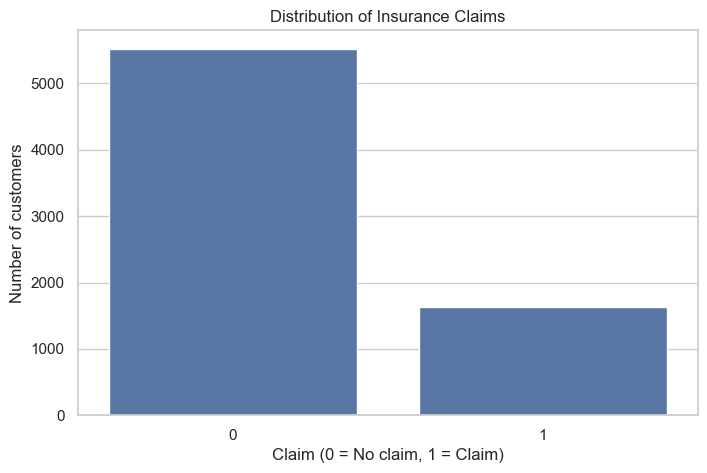

Claim
0    77.178771
1    22.821229
Name: proportion, dtype: float64


In [7]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=train,
    x="Claim"
)

plt.title("Distribution of Insurance Claims")
plt.xlabel("Claim (0 = No claim, 1 = Claim)")
plt.ylabel("Number of customers")

plt.show()

# Calculate percentages
print(train["Claim"].value_counts(normalize=True) * 100)


### 4.2 Distribution of numerical features
Histograms of the main numeric columns show each variable's shape, spread and skewness. Skewed distributions may benefit from a log transform later. Note that `Building_Type` appears here but may be a coded category rather than a true continuous measurement.

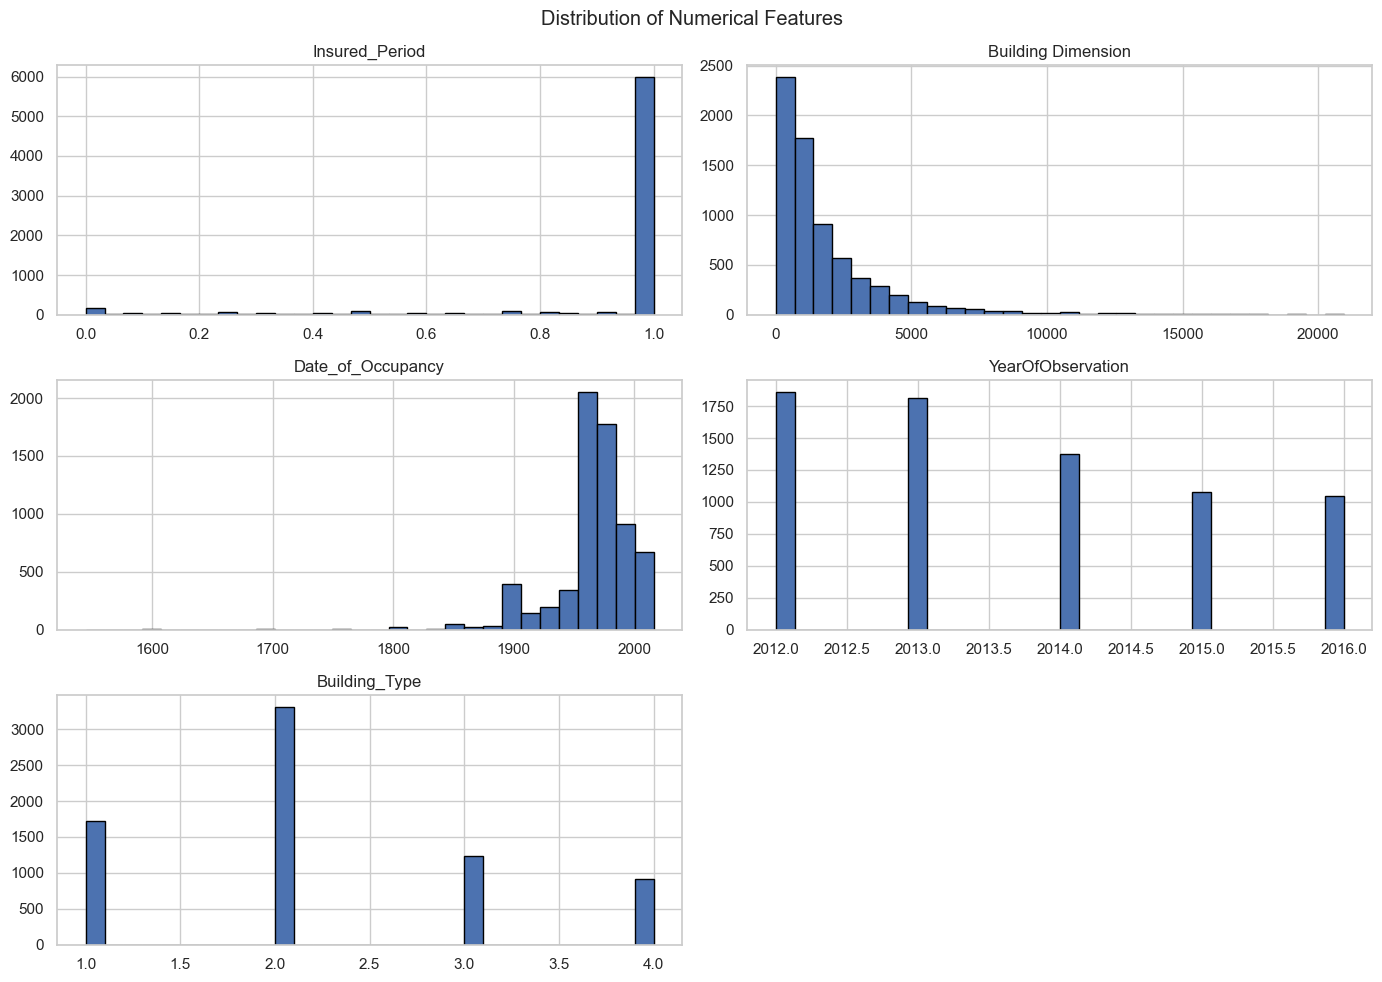

In [8]:

numerical_columns = [
    "Insured_Period",
    "Building Dimension",
    "Date_of_Occupancy",
    "YearOfObservation",
    "Building_Type"
]

train[numerical_columns].hist(
    bins=30,
    figsize=(14, 10),
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()


### 4.3 Correlation matrix
A heatmap of pairwise correlations between numeric columns, including the target. It highlights which features move together with `Claim` and flags strongly correlated features that may be redundant.

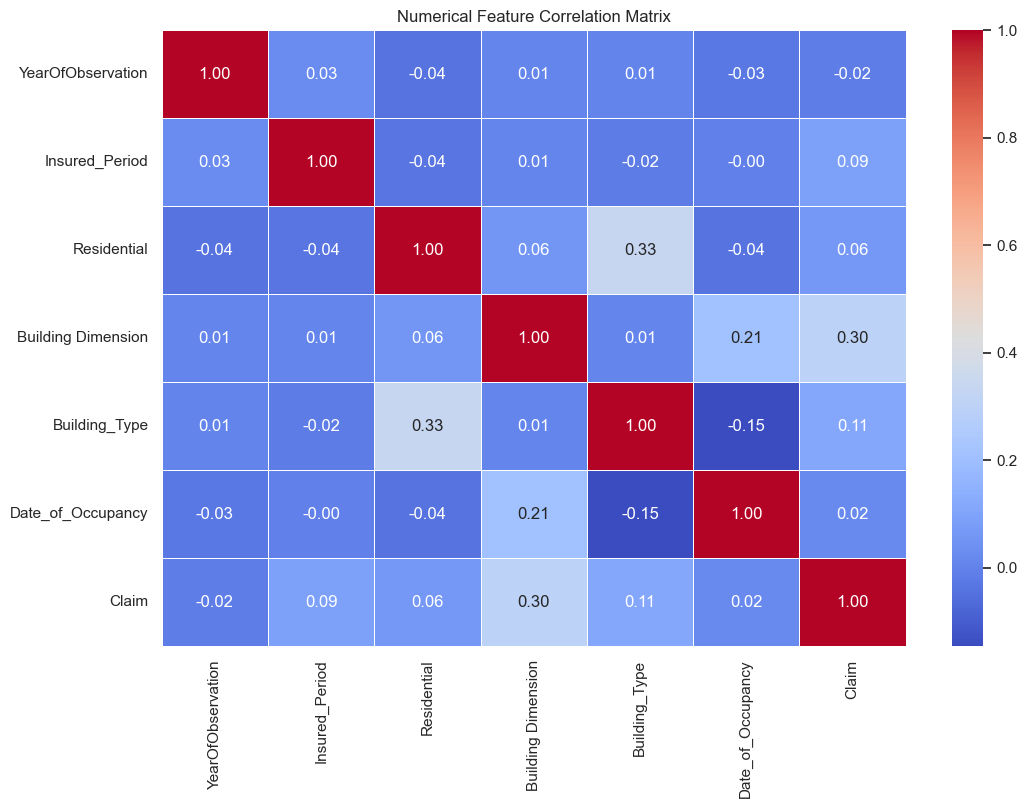

In [9]:

correlation = train.select_dtypes(
    include=["number"]
).corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Numerical Feature Correlation Matrix")
plt.show()


### 4.4 Outlier investigation with boxplots
Boxplots for four numeric features. Points beyond the whiskers are potential outliers (values unusually far from the bulk of the data). This is a visual first pass before measuring outliers numerically.

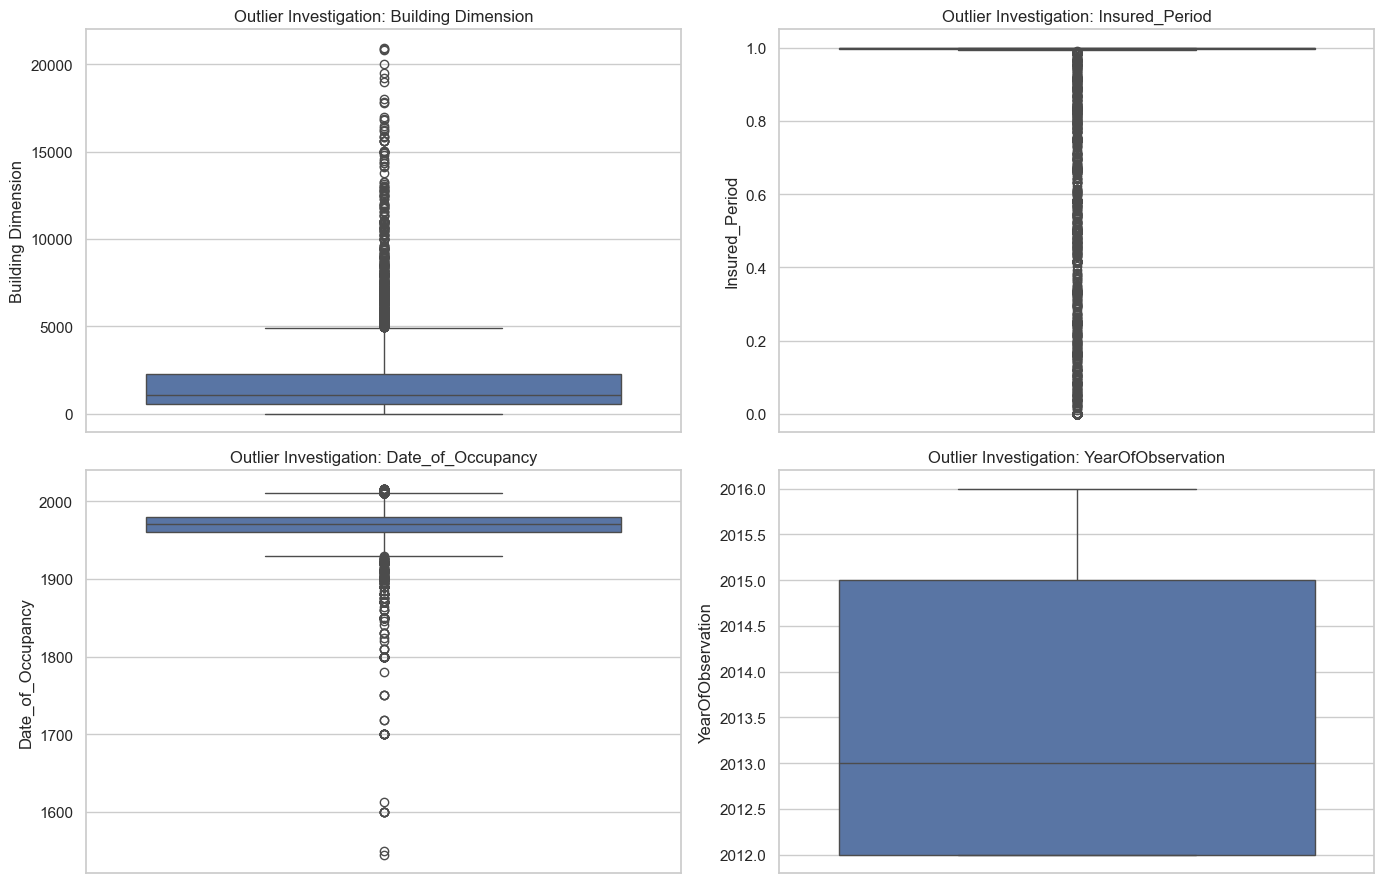

In [10]:

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

columns = [
    "Building Dimension",
    "Insured_Period",
    "Date_of_Occupancy",
    "YearOfObservation"
]

for ax, column in zip(axes.flatten(), columns):

    sns.boxplot(
        data=train,
        y=column,
        ax=ax
    )

    ax.set_title(f"Outlier Investigation: {column}")

plt.tight_layout()
plt.show()


### 4.5 Building dimension vs. claims
Compare the distribution of `Building Dimension` between customers who did and did not file a claim. This shows whether building size is associated with claim likelihood and whether extreme sizes are concentrated in one class.

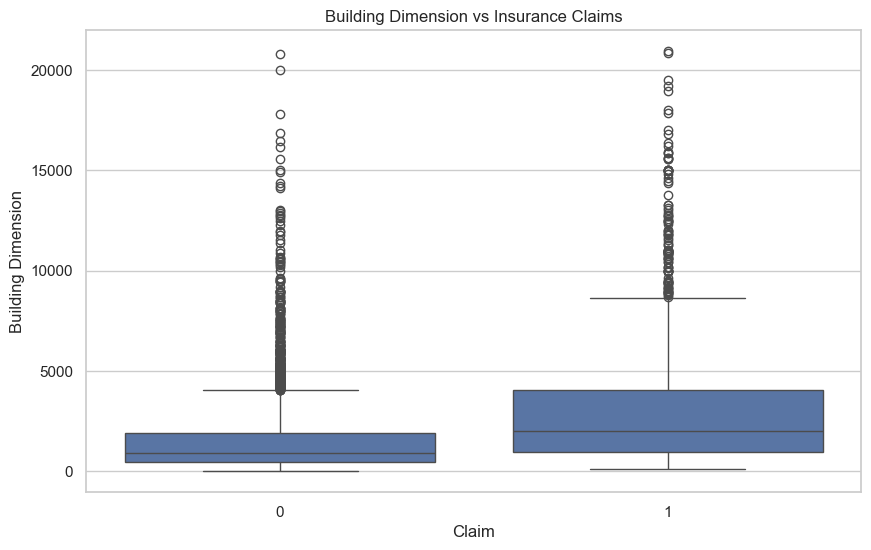

In [11]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=train,
    x="Claim",
    y="Building Dimension"
)

plt.title("Building Dimension vs Insurance Claims")
plt.xlabel("Claim")
plt.ylabel("Building Dimension")

plt.show()


## 5. Outlier Detection and Treatment

### 5.1 Compute IQR outlier boundaries
Use the **IQR (interquartile range) rule** on three continuous features:

- `IQR = Q3 − Q1`
- Lower bound = `Q1 − 1.5 × IQR`
- Upper bound = `Q3 + 1.5 × IQR`

Bounds are calculated from the training data only, stored in a dictionary, and the number of values outside the bounds is reported for each feature.

In [12]:

# Select continuous numerical features
numeric_features = [
    "Insured_Period",
    "Building Dimension",
    "Date_of_Occupancy"
]

# Calculate outlier boundaries using training data
outlier_bounds = {}

for column in numeric_features:
    Q1 = train[column].quantile(0.25)
    Q3 = train[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_bounds[column] = (lower, upper)

    # Count outliers
    outliers = train[
        (train[column] < lower) |
        (train[column] > upper)
    ]

    print(f"\n{column}")
    print("Lower boundary:", lower)
    print("Upper boundary:", upper)
    print("Number of outliers:", len(outliers))



Insured_Period
Lower boundary: 0.9931693999999999
Upper boundary: 1.00409836
Number of outliers: 1237

Building Dimension
Lower boundary: -2114.625
Upper boundary: 4932.375
Number of outliers: 540

Date_of_Occupancy
Lower boundary: 1930.0
Upper boundary: 2010.0
Number of outliers: 908


### 5.2 Inspect the outlier records
Show the first 15 outlier rows for each feature alongside their `Claim` label. Before removing or altering anything, check whether outliers are genuine errors or legitimate extreme cases that may carry predictive signal (for example, very large buildings that claim more often).

In [13]:

for column in numeric_features:
    lower, upper = outlier_bounds[column]

    outliers = train[
        (train[column] < lower) |
        (train[column] > upper)
    ]

    print(f"\nOutliers in {column}:")
    print(outliers[[column, "Claim"]].head(15))



Outliers in Insured_Period:
     Insured_Period  Claim
10         0.241096      0
13         0.843836      0
20         0.956284      0
35         0.084932      0
57         0.857534      0
61         0.295890      0
93         0.000000      0
94         0.000000      0
104        0.781421      1
110        0.915068      0
116        0.986301      0
123        0.084932      0
134        0.161644      0
147        0.095890      0
159        0.665753      0

Outliers in Building Dimension:
     Building Dimension  Claim
7                4952.0      0
25               5439.0      0
26               5439.0      1
70               6510.0      1
110              9570.0      0
124              5419.0      1
125              5419.0      1
146              5610.0      1
162              5586.0      0
163              5586.0      0
170              7063.0      1
180             18000.0      1
189              9920.0      1
191              5350.0      0
200              7887.0      1

Outliers 

### 5.3 Treat outliers by capping (winsorizing)
Rather than deleting rows, extreme `Building Dimension` values are **clipped** to the IQR boundaries. This keeps every record while limiting the influence of extremes.

- Work on copies (`train_clean`, `test_clean`) so the raw data stays untouched.
- Boundaries come from the training data and are applied to both sets, so no test information leaks in.

In [14]:

# Create copies so original datasets remain unchanged
train_clean = train.copy()
test_clean = test.copy()

# Calculate IQR boundaries using training data only
Q1 = train_clean["Building Dimension"].quantile(0.25)
Q3 = train_clean["Building Dimension"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Apply the same boundaries to training and test data
train_clean["Building Dimension"] = (
    train_clean["Building Dimension"].clip(lower, upper)
)

test_clean["Building Dimension"] = (
    test_clean["Building Dimension"].clip(lower, upper)
)

print("Lower boundary:", lower)
print("Upper boundary:", upper)

print("\nOutlier treatment completed.")


Lower boundary: -2114.625
Upper boundary: 4932.375

Outlier treatment completed.


### 5.4 Before vs. after comparison
Side-by-side boxplots of `Building Dimension` before and after capping, confirming the treatment removed the extreme values without distorting the main distribution.

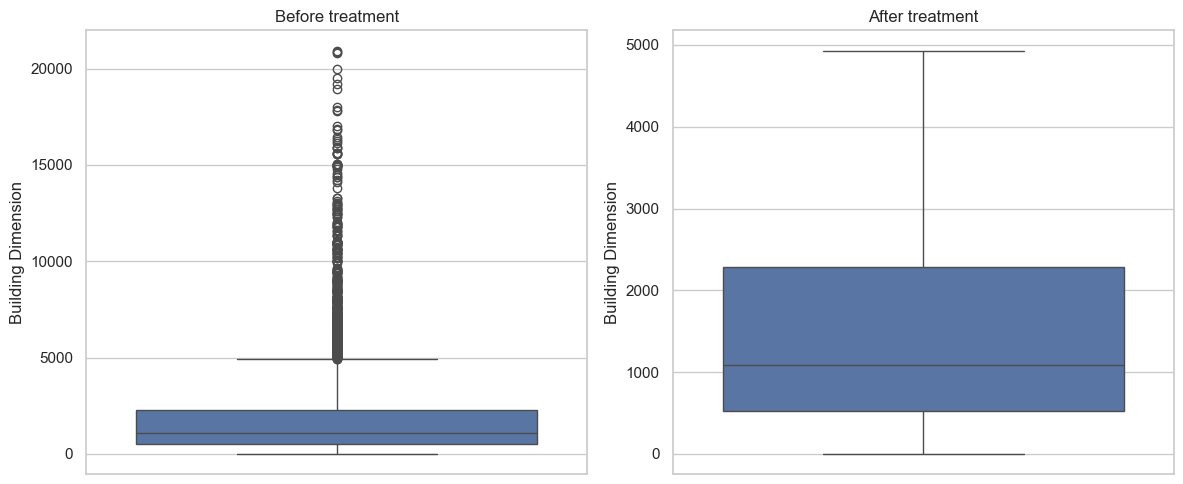

In [15]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=train["Building Dimension"], ax=axes[0])
axes[0].set_title("Before treatment")

sns.boxplot(y=train_clean["Building Dimension"], ax=axes[1])
axes[1].set_title("After treatment")

plt.tight_layout()
plt.show()


## 6. Data Cleaning

### 6.1 Normalize missing-value markers
Replace any remaining `"."` placeholders with `NaN` across the entire cleaned datasets (not just `NumberOfWindows`), then print the missing-value count per column. This gives the baseline for imputation.

In [16]:

import numpy as np
import pandas as pd

# Normalize the missing-value marker
train_clean = train_clean.replace(".", np.nan)
test_clean = test_clean.replace(".", np.nan)

# Check missing values in both datasets
print("TRAINING DATA MISSING VALUES")
print(train_clean.isnull().sum())

print("\nTEST DATA MISSING VALUES")
print(test_clean.isnull().sum())


TRAINING DATA MISSING VALUES
Customer Id             0
YearOfObservation       0
Insured_Period          0
Residential             0
Building_Painted        0
Building_Fenced         0
Garden                  7
Settlement              0
Building Dimension    106
Building_Type           0
Date_of_Occupancy     508
NumberOfWindows         0
Geo_Code              102
Claim                   0
dtype: int64

TEST DATA MISSING VALUES
Customer Id              0
YearOfObservation        0
Insured_Period           0
Residential              0
Building_Painted         0
Building_Fenced          0
Garden                   4
Settlement               0
Building Dimension      13
Building_Type            0
Date_of_Occupancy      728
NumberOfWindows       2240
Geo_Code                13
dtype: int64


### 6.2 Define feature groups
Split the columns into **numerical** and **categorical** lists. Each group needs a different imputation strategy: medians for numbers, an `"Unknown"` label for categories. Codes such as `Geo_Code` and `Building_Type` are treated as categories because their numeric values have no real order.

In [17]:

# Numerical features
numeric_features = [
    "Insured_Period",
    "Building Dimension",
    "Date_of_Occupancy",
    "YearOfObservation"
]

# Categorical features
categorical_features = [
    "Residential",
    "Building_Painted",
    "Building_Fenced",
    "Garden",
    "Settlement",
    "Building_Type",
    "NumberOfWindows",
    "Geo_Code"
]

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)


Numerical features: ['Insured_Period', 'Building Dimension', 'Date_of_Occupancy', 'YearOfObservation']
Categorical features: ['Residential', 'Building_Painted', 'Building_Fenced', 'Garden', 'Settlement', 'Building_Type', 'NumberOfWindows', 'Geo_Code']


### 6.3 Impute numerical features
1. Convert numeric columns with `pd.to_numeric(errors="coerce")`, turning any stray text into `NaN`.
2. Compute the **median** of each column on the training data.
3. Fill missing values in both train and test with those training medians.

The median is used because it is robust to outliers and skewed data.

In [18]:

# Convert numerical columns to numeric format
for column in numeric_features:
    train_clean[column] = pd.to_numeric(
        train_clean[column], errors="coerce"
    )

    test_clean[column] = pd.to_numeric(
        test_clean[column], errors="coerce"
    )

# Calculate medians from training data only
numeric_medians = train_clean[numeric_features].median()

# Fill missing numerical values
train_clean[numeric_features] = (
    train_clean[numeric_features].fillna(numeric_medians)
)

test_clean[numeric_features] = (
    test_clean[numeric_features].fillna(numeric_medians)
)

print("Numerical imputation completed.")


Numerical imputation completed.


### 6.4 Impute categorical features
Cast categorical columns to the string type and fill missing values with the explicit label `"Unknown"`. Treating "missing" as its own category keeps the rows and lets the model learn whether missingness itself is informative.

In [19]:

for column in categorical_features:

    train_clean[column] = (
        train_clean[column].astype("string").fillna("Unknown")
    )

    test_clean[column] = (
        test_clean[column].astype("string").fillna("Unknown")
    )

print("Categorical imputation completed.")


Categorical imputation completed.


### 6.5 Confirm no missing values remain
Total remaining missing values in the cleaned training and test sets. Both should be `0` after imputation.

In [20]:

print("Remaining missing values in training data:")
print(train_clean.isnull().sum().sum())

print("\nRemaining missing values in test data:")
print(test_clean.isnull().sum().sum())


Remaining missing values in training data:
0

Remaining missing values in test data:
0


## 7. Validation of the Cleaned Data

### 7.1 Shape comparison
Compare dimensions before and after cleaning to verify that **no rows or columns were accidentally lost**. Cleaning should change values, not the structure.

In [21]:

print("Original training shape:", train.shape)
print("Cleaned training shape:", train_clean.shape)

print("\nOriginal test shape:", test.shape)
print("Cleaned test shape:", test_clean.shape)


Original training shape: (7160, 14)
Cleaned training shape: (7160, 14)

Original test shape: (3069, 13)
Cleaned test shape: (3069, 13)


### 7.2 Final integrity checks
Final check for missing values and duplicate rows in the cleaned datasets, confirming they are ready for feature engineering.

In [22]:

print("Missing values in training:", train_clean.isnull().sum().sum())
print("Missing values in test:", test_clean.isnull().sum().sum())

print("\nDuplicate rows in training:", train_clean.duplicated().sum())
print("Duplicate rows in test:", test_clean.duplicated().sum())


Missing values in training: 0
Missing values in test: 0

Duplicate rows in training: 0
Duplicate rows in test: 0


### 7.3 Cleaned numerical summary
Descriptive statistics for the cleaned numeric features. Verify that ranges are sensible (for example, a plausible `Insured_Period` and realistic years) after outlier capping and imputation.

In [23]:

print(train_clean[numeric_features].describe().T)


                     count         mean          std     min          25%  \
Insured_Period      7160.0     0.909758     0.239756     0.0     0.997268   
Building Dimension  7160.0  1632.065852  1432.626170     1.0   531.500000   
Date_of_Occupancy   7160.0  1964.849721    34.730347  1545.0  1960.000000   
YearOfObservation   7160.0  2013.669553     1.383769  2012.0  2012.000000   

                       50%     75%       max  
Insured_Period         1.0     1.0     1.000  
Building Dimension  1083.0  2250.0  4932.375  
Date_of_Occupancy   1970.0  1980.0  2016.000  
YearOfObservation   2013.0  2015.0  2016.000  


### 7.4 Post-cleaning distributions
Histograms with density curves (KDE) for each numeric feature after cleaning, to check that cleaning did not introduce unnatural spikes (for instance, a large spike at the median from imputation).

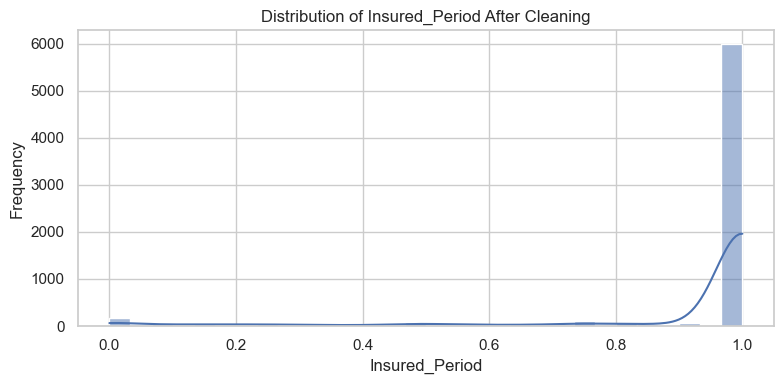

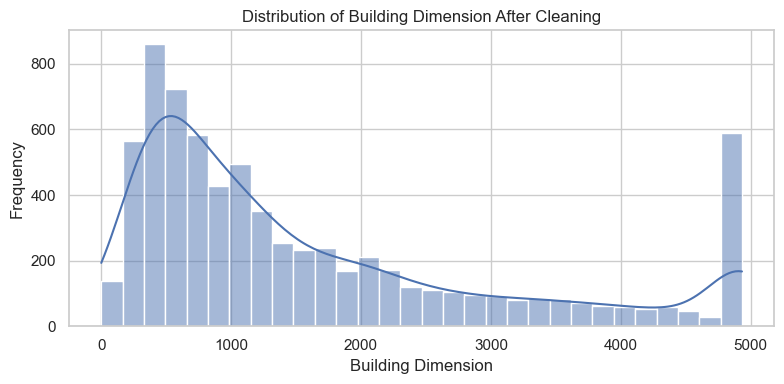

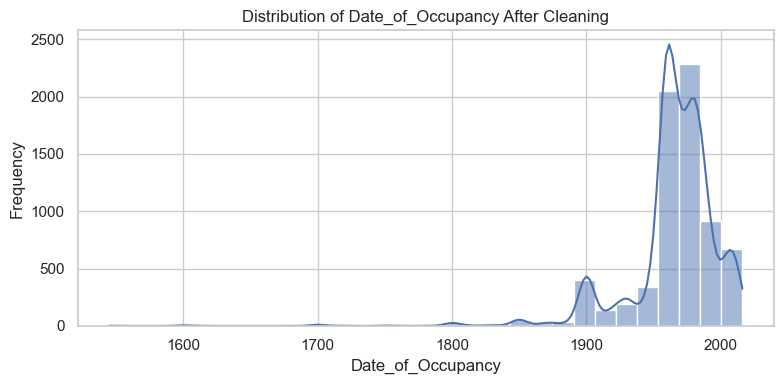

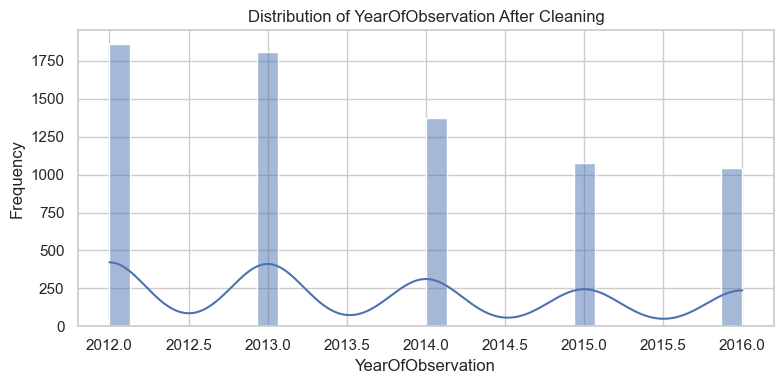

In [24]:

import matplotlib.pyplot as plt
import seaborn as sns

for column in numeric_features:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=train_clean,
        x=column,
        kde=True,
        bins=30
    )

    plt.title(f"Distribution of {column} After Cleaning")
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()


### 7.5 Target distribution after cleaning
Re-check the `Claim` class balance on the cleaned data. It should match the original distribution, since cleaning should never alter the target.

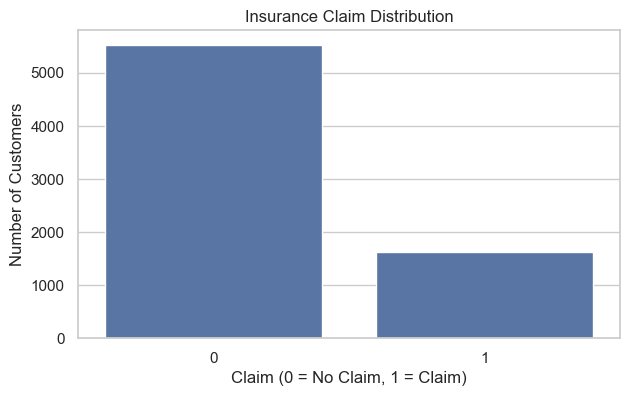

Claim
0    77.178771
1    22.821229
Name: proportion, dtype: float64


In [25]:

plt.figure(figsize=(7, 4))

sns.countplot(
    data=train_clean,
    x="Claim"
)

plt.title("Insurance Claim Distribution")
plt.xlabel("Claim (0 = No Claim, 1 = Claim)")
plt.ylabel("Number of Customers")

plt.show()

print(train_clean["Claim"].value_counts(normalize=True) * 100)



## 8. Feature Engineering

### 8.1 Separate features and target
- Create independent copies of the cleaned data for modeling.
- Store the test `Customer Id` values for building the final submission file.
- Split off the target `y = Claim`.
- Drop `Claim` and `Customer Id` from the inputs. The ID is only an identifier and carries no predictive meaning.

In [26]:
#creating  missing  values
# Create independent copies
train_fe = train_clean.copy()
test_fe = test_clean.copy()

# Save customer IDs for later predictions
test_customer_ids = test_fe["Customer Id"].copy()

# Separate target variable
y = train_fe["Claim"].copy()

# Remove target and customer ID from model inputs
X_train = train_fe.drop(
    columns=["Claim", "Customer Id"]
)

X_test = test_fe.drop(
    columns=["Customer Id"]
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)


Training features: (7160, 12)
Testing features: (3069, 12)


### 8.2 Create `Building_Age`
`Building_Age = YearOfObservation − Date_of_Occupancy`

Age is likely more informative about structural condition and risk than a raw year. The cell also counts **negative ages**, which are impossible and would indicate data errors (occupancy dated after the observation year), and prints summary statistics.

In [27]:

# Calculate building age
X_train["Building_Age"] = (
    X_train["YearOfObservation"] -
    X_train["Date_of_Occupancy"]
)

X_test["Building_Age"] = (
    X_test["YearOfObservation"] -
    X_test["Date_of_Occupancy"]
)

# Inspect impossible negative ages
print("Negative building ages in training:",
      (X_train["Building_Age"] < 0).sum())

print("Negative building ages in testing:",
      (X_test["Building_Age"] < 0).sum())

print("\nBuilding age statistics:")
print(X_train["Building_Age"].describe())


Negative building ages in training: 0
Negative building ages in testing: 0

Building age statistics:
count    7160.000000
mean       48.819832
std        34.799675
min         0.000000
25%        32.000000
50%        44.000000
75%        55.000000
max       469.000000
Name: Building_Age, dtype: float64


### 8.3 Log-transform building dimension
Check that no dimensions are negative, then create `Building_Dimension_Log = log(1 + Building Dimension)`. The log transform reduces right-skew and compresses large values, which helps many models. `log1p` is used so zero values are handled safely.

In [28]:

import numpy as np

# Check that dimensions are non-negative
print("Negative dimensions in training:",
      (X_train["Building Dimension"] < 0).sum())

print("Negative dimensions in testing:",
      (X_test["Building Dimension"] < 0).sum())
#feature engineering
# Create logarithmic features
X_train["Building_Dimension_Log"] = np.log1p(
    X_train["Building Dimension"]
)

X_test["Building_Dimension_Log"] = np.log1p(
    X_test["Building Dimension"]
)

print("Logarithmic features created.")


Negative dimensions in training: 0
Negative dimensions in testing: 0
Logarithmic features created.


### 8.4 Add missingness indicators
For columns that originally had missing information, add binary flags (`<column>_Was_Missing`, 1 = value was missing). Imputation hides the fact that a value was absent, and that absence can itself be predictive. The flags are computed from the **original** datasets.

In [29]:

# Columns that originally contained missing information
missing_columns = [
    "Garden",
    "Building Dimension",
    "Date_of_Occupancy",
    "Geo_Code",
    "NumberOfWindows"
]

for column in missing_columns:

    # Check original training data
    train_missing = (
        train[column].isna() |
        train[column].astype("string").eq(".")
    )

    # Check original testing data
    test_missing = (
        test[column].isna() |
        test[column].astype("string").eq(".")
    )

    X_train[column + "_Was_Missing"] = (
        train_missing.astype(int)
    )

    X_test[column + "_Was_Missing"] = (
        test_missing.astype(int)
    )

print("Missingness indicators created.")


Missingness indicators created.


### 8.5 Verify the engineered features
Summary statistics for the new features, the updated dataset shapes, and a final missing-value check to confirm the feature engineering step introduced no gaps.

In [30]:

new_features = [
    "Building_Age",
    "Building_Dimension_Log"
]

print(X_train[new_features].describe())

print("\nNew training dataset shape:", X_train.shape)
print("New testing dataset shape:", X_test.shape)

print("\nMissing values in engineered training data:",
      X_train.isnull().sum().sum())

print("Missing values in engineered testing data:",
      X_test.isnull().sum().sum())


       Building_Age  Building_Dimension_Log
count   7160.000000             7160.000000
mean      48.819832                6.990907
std       34.799675                0.967604
min        0.000000                0.693147
25%       32.000000                6.277582
50%       44.000000                6.988413
75%       55.000000                7.719130
max      469.000000                8.503779

New training dataset shape: (7160, 19)
New testing dataset shape: (3069, 19)

Missing values in engineered training data: 0
Missing values in engineered testing data: 0


### 8.6 Visualize the new features
Histograms of `Building_Age` and `Building_Dimension_Log` to confirm their distributions look reasonable and that the log transform reduced the skew.

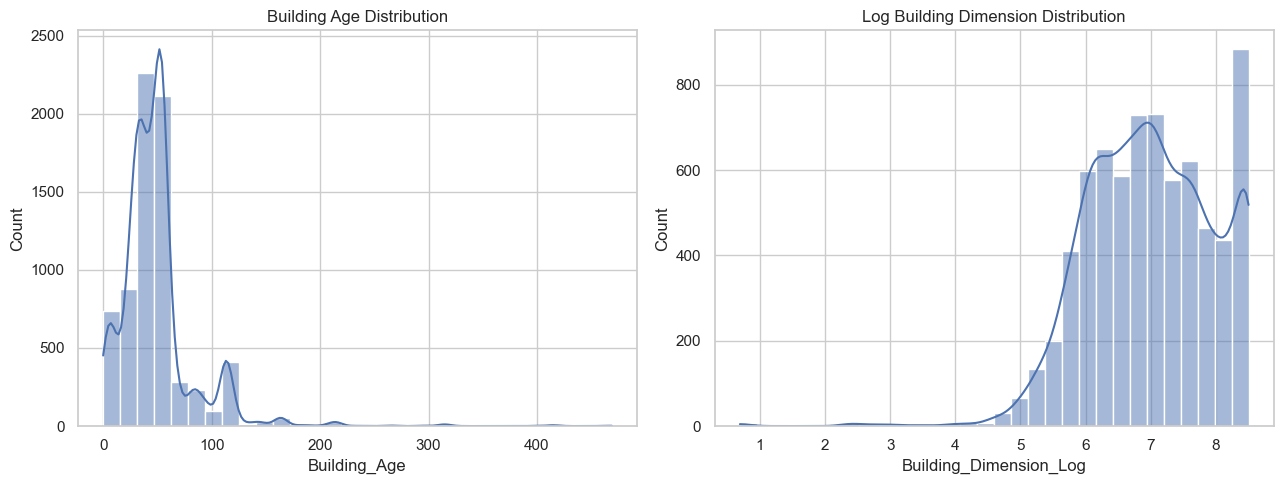

In [31]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    X_train["Building_Age"],
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Building Age Distribution")

sns.histplot(
    X_train["Building_Dimension_Log"],
    bins=30,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Log Building Dimension Distribution")

plt.tight_layout()
plt.show()


## 9. Preprocessing Pipeline

### 9.1 Identify column types
Automatically detect categorical and numerical columns in the engineered training set. This list drives the preprocessing pipeline and automatically includes the new engineered and indicator columns.

In [32]:

# Identify categorical columns
categorical_columns = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

# Identify numerical columns
numerical_columns = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

print("\nNumerical columns:")
print(numerical_columns)


Categorical columns:
['Residential', 'Building_Painted', 'Building_Fenced', 'Garden', 'Settlement', 'Building_Type', 'NumberOfWindows', 'Geo_Code']

Numerical columns:
['YearOfObservation', 'Insured_Period', 'Building Dimension', 'Date_of_Occupancy', 'Building_Age', 'Building_Dimension_Log', 'Garden_Was_Missing', 'Building Dimension_Was_Missing', 'Date_of_Occupancy_Was_Missing', 'Geo_Code_Was_Missing', 'NumberOfWindows_Was_Missing']


### 9.2 Check category cardinality
Count unique values in each categorical column. **High-cardinality** columns (such as `Geo_Code`) produce many columns after one-hot encoding, which affects model size, memory use and overfitting risk.

In [33]:

for column in categorical_columns:
    print(
        column,
        ":", X_train[column].nunique(),
        "unique categories"
    )


Residential : 2 unique categories
Building_Painted : 2 unique categories
Building_Fenced : 2 unique categories
Garden : 3 unique categories
Settlement : 2 unique categories
Building_Type : 4 unique categories
NumberOfWindows : 11 unique categories
Geo_Code : 1308 unique categories


### 9.3 Build the preprocessing pipeline
A `ColumnTransformer` applies different steps to each column type:

| Column type | Steps |
|---|---|
| Numerical | Median imputation |
| Categorical | Fill with `"Unknown"`, then one-hot encode (`handle_unknown="ignore"` so unseen categories in test data don't cause errors) |

Packaging preprocessing in a pipeline guarantees identical transformations on every dataset and prevents data leakage during validation.

In [34]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Treat all categorical columns as strings
categorical_columns = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

numerical_columns = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("numerical", numeric_pipeline, numerical_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

print("Preprocessing pipeline created.")


Preprocessing pipeline created.


### 9.4 Fit and apply the encoder
`fit_transform` on the training features (learn the categories and medians), then `transform` on the test features using what was learned. The test set must never be used for fitting. The printed shapes should show the **same number of columns** for both.

In [35]:

# Fit only on training features
X_train_encoded = preprocessor.fit_transform(X_train)

# Apply the learned transformation to test features
X_test_encoded = preprocessor.transform(X_test)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)


Encoded training shape: (7160, 1345)
Encoded testing shape: (3069, 1345)


### 9.5 Final shape and quality check
Confirm that the target and feature matrices have matching row counts and that the encoded training matrix contains no `NaN` values. The check handles both sparse and dense outputs.

In [36]:

print("Training target shape:", y.shape)

print("Training features shape:", X_train_encoded.shape)
print("Testing features shape:", X_test_encoded.shape)

print("Missing values in training:",
      np.isnan(X_train_encoded.data).sum()
      if hasattr(X_train_encoded, "data")
      else np.isnan(X_train_encoded).sum())


Training target shape: (7160,)
Training features shape: (7160, 1345)
Testing features shape: (3069, 1345)
Missing values in training: 0


## 10. Train/Validation Split

### 10.1 Create a stratified validation set
Hold out 20% of the training data for validation, with `random_state=42` for reproducibility and `stratify=y` so both parts keep the same claim/no-claim ratio, which matters for an imbalanced target.

The split is done on the **raw engineered features** (`X_train`), not the already-encoded matrix, so the pipeline can later be fitted only on the training portion without leaking validation information.

In [37]:
#splitting  data

from sklearn.model_selection import train_test_split

# Split raw features, not previously encoded features
X_train_split, X_valid, y_train_split, y_valid = train_test_split(
    X_train,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Model training rows:", X_train_split.shape[0])
print("Validation rows:", X_valid.shape[0])

print("\nTraining claim distribution:")
print(y_train_split.value_counts(normalize=True))

print("\nValidation claim distribution:")
print(y_valid.value_counts(normalize=True))


Model training rows: 5728
Validation rows: 1432

Training claim distribution:
Claim
0    0.771823
1    0.228177
Name: proportion, dtype: float64

Validation claim distribution:
Claim
0    0.771648
1    0.228352
Name: proportion, dtype: float64


                           Feature  Importance  RF_Importance
0               Building Dimension     0.14111        0.05185
1                   Insured_Period     0.02107        0.01555
2                    Building_Type     0.01429        0.01063
3                Date_of_Occupancy     0.00699        0.00176
4                     Building_Age     0.00571        0.00000
5                         Geo_Code     0.00345        0.00455
6                      Residential     0.00219        0.00489
7           Building_Dimension_Log     0.00187        0.05462
8                  Building_Fenced     0.00151       -0.00101
9    Date_of_Occupancy_Was_Missing     0.00122       -0.00006
10                          Garden     0.00083       -0.00054
11                 NumberOfWindows     0.00052        0.01607
12                Building_Painted     0.00027        0.00223
13     NumberOfWindows_Was_Missing     0.00000        0.00000
14              Garden_Was_Missing     0.00000       -0.00000
15  Buil

## 11. Feature Selection

### 11.1 Feature importance ranking
Display the features sorted by importance (with the standard deviation across repeats), so the most predictive features can be kept and the weakest dropped.

> ⚠️ This cell expects an `importance_df` DataFrame (for example from permutation importance or a tree model), which must be created in an earlier cell. The model training cell above (currently empty) needs to define it first.

In [71]:
#feature  selection

# Display features ranked by importance

print(
    importance_df[
        ["Feature", "Importance", "Std"]
    ].sort_values(
        by="Importance",
        ascending=False
    ).round(5)
)


                           Feature  Importance      Std
7               Building Dimension     0.14111  0.01455
1                   Insured_Period     0.02107  0.00614
8                    Building_Type     0.01429  0.00607
9                Date_of_Occupancy     0.00699  0.00514
12                    Building_Age     0.00571  0.00838
11                        Geo_Code     0.00345  0.00529
2                      Residential     0.00219  0.00110
13          Building_Dimension_Log     0.00187  0.00494
4                  Building_Fenced     0.00151  0.00076
16   Date_of_Occupancy_Was_Missing     0.00122  0.00053
5                           Garden     0.00083  0.00029
10                 NumberOfWindows     0.00052  0.00480
3                 Building_Painted     0.00027  0.00036
18     NumberOfWindows_Was_Missing     0.00000  0.00000
14              Garden_Was_Missing     0.00000  0.00000
15  Building Dimension_Was_Missing    -0.00009  0.00018
6                       Settlement    -0.00011  